# Which plane validates the ABCD estimate of the displaced search region?

The search region of the 2μ2e channel is the isolated, back-to-back corner of the $|\Delta\phi|$ ×
leading-muon-LJ-isolation plane with both lepton jets (LJs) displaced and the LJ-pair mass above
150 GeV: leading muon LJ isolation < 0.25, the egamma LJ isolation < 0.5, $|\Delta\phi| \ge 2.4$.
The estimate is an ABCD in that plane, $A = B\,C/D$ with buffers (isolation fails at ≥ 0.5,
$|\Delta\phi|$ fails below 2.0). Three facts set the problem:

- the plane cannot be validated where it is used, because A is the search region;
- the open regions of the search plane hold a few tens of events in B and about ten each in C and
  D, so the in-plane estimate alone has a 50% statistical error and no usable one above a pair
  mass of 300 GeV;
- the simulation's search-region yield rests on a handful of effective events (about one in
  Dongyub's status report, 4.8 for the region defined here, section 5) and it does not describe
  the isolation–$|\Delta\phi|$ correlation (`transfer_factors.ipynb`, section 5).

So the closure correction κ = A D/(B C) and any factor that replaces an in-plane ratio have to come
from a plane where A is open. The plane used so far is the one with both LJs prompt (PP). This
notebook asks which open plane can stand in for the search plane, finds that PP cannot and that the
plane with a prompt muon LJ and a displaced egamma LJ (PD) is the better candidate, and assembles
the background estimate from that: an in-plane estimate corrected by κ measured in PD, or the B
count of the search plane times the A/B ratio measured in PD, separately for the muon LJs with 1–2
pixel hits and for those with none. The numbers are for the recipe to be agreed on; nothing here
looks at the search region.

**Inputs.** Dongyub Lee's inclusive six-dimensional histograms of the 2018 data and simulation
(campaign `ABCD_6D_inclusive_eHEM_skimv1`, read-only copies made by `fetch_6d.sh`), the same ones as
in `transfer_factors.ipynb`, whose definitions apply unchanged: object 0 is the leading muon LJ and
object 1 the leading egamma LJ (2μ2e) or the subleading muon LJ (4μ); a muon LJ is displaced when
its maximum pixel-hit count is ≤ 2 and an egamma LJ when its minimum lost-hit count is ≥ 1 (photon-only
LJs carry the sentinel 999 and are displaced); the planes PP, DP, PD and DD name the (object 0,
object 1) displacement states. New here are the finer planes that split a plane by the stored
displacement variable itself, written `PD:mu3` (muon LJ with exactly 3 pixel hits), `DD:mu1-2`,
`DD:mu0`, `PD:g` (photon-only egamma LJ), `PD:e` (electron with ≥ 1 lost hit); a split that lies
outside its plane is refused by the code. Regions follow `transfer_lib`: B fails the isolation and
passes $|\Delta\phi|$, C the reverse, D fails both, so κ = (A/C)/(B/D) and A/B is the isolation
pass/fail ratio among the back-to-back events, the ratio the search region needs. The reference
numbers quoted for the validation plane (κ = 0.76 ± 0.10 in 2μ2e and 1.38 ± 0.37 in 4μ without
buffers, and a κ rising with the $|\Delta\phi|$ boundary) are from Dongyub's status report of
2026-10-08 and were reproduced in section 0 of `transfer_factors.ipynb`.

**Blinding.** The data cube is loaded only through `transfer_lib.summed_cubes`, which hides the
corner of the DD plane at mass ≥ 150 GeV with both isolations below 0.5 and $|\Delta\phi| \ge 2$,
and in 4μ the same corners of the DP and PD planes; any projection touching a hidden cell prints
as "blind" or NaN. Everything else is open, and this notebook uses: the search plane's B, C and D,
its corner below 150 GeV, and the isolated corners of the 2μ2e DP and PD planes. The region of the
search plane with the egamma LJ non-isolated (isolation ≥ 0.5) and the muon LJ isolated at
$|\Delta\phi| \ge 2$ and M ≥ 150 GeV is also outside the hidden box; it was used in
`transfer_factors.ipynb` and is not used here for 2μ2e, while section 6 does use its 4μ
counterpart (subleading muon LJ non-isolated) as a region of the plane of the two isolations. As
in that notebook, looking at the open corners is a change of practice to be agreed with the
group, and section 5 shows how much signal the isolated corners of DP and PD hold.

**Uncertainties.** Ratios of disjoint data counts carry 68.27% Clopper–Pearson intervals; ratios
of ratios (κ, and every "step" below) add the relative errors in quadrature, which gives slightly
wider κ intervals than the symmetric propagation of `transfer_factors.ipynb` (0.84 ± 0.12 here
against 0.84 ± 0.11 there for the same number); a count of zero times a factor carries 1.84 ×
factor upward (the upper edge of the central 68% interval for an observed zero). Pulls between
two ratios are taken in log space. Shape comparisons use the pooled two-sample χ²; the slices of
the search plane hold 33 and 69 events over a dozen bins, so those p-values are indicative.
$N_{\text{eff}}$ of a simulated yield is (sum of weights)² / (sum of squared weights), the
unweighted count with the same relative error.

In [1]:
import dataclasses
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import plane_search_plots as pp

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE = tl.local_dir()
print("inputs:", BASE)
data = tl.summed_cubes(BASE, "data")       # always blinded; nothing of the hidden box is printed
print("hidden box:", io.blind_signature())
for t, c in data.items():
    print(f"{t}: {int(np.isnan(c.sumw).sum())} hidden cells")
d2 = data["2mu2e"]
NOMINAL = ps.Config()
print("nominal configuration:", NOMINAL.label())

inputs: /uscms_data/d3/murtazas/abcd6d_local


hidden box: iso<0.5 mass>=150 dphi>=2 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
2mu2e: 320760 hidden cells
4mu: 769824 hidden cells
nominal configuration: dphi 2.4/2 x iso0 0.25/0.5, iso1<0.5, M>=150


## 1. The $|\Delta\phi|$ boundaries

The planned search region uses $|\Delta\phi| \ge 2.4$ (or 2.6) with the fail region below 2.0.
The pass boundary defines A and B, the fail boundary C and D. Below, κ of PP, PD and PD's
photon-only part against the pass boundary, with the fail boundary fixed at 2.0 (left) and moving
with it (right); the points of a series are nested selections and therefore correlated. The table
gives the signal acceptance of each pass boundary relative to 2.0 for seven signal points, and the
signal fractions that leak into B, C and D of the search plane for the nominal boundaries.

How to read it: with the fail boundary fixed, κ of every plane is flat against the pass boundary;
when the two move together, κ of PP rises from 0.82 to 1.02 between 2.0 and 2.6, so a trend of
that kind comes from what the fail boundary does to C and D, not from the definition of A. The
pass boundary is then a matter of signal acceptance (which favours 2.0) and of the buffer wanted
between A and C.

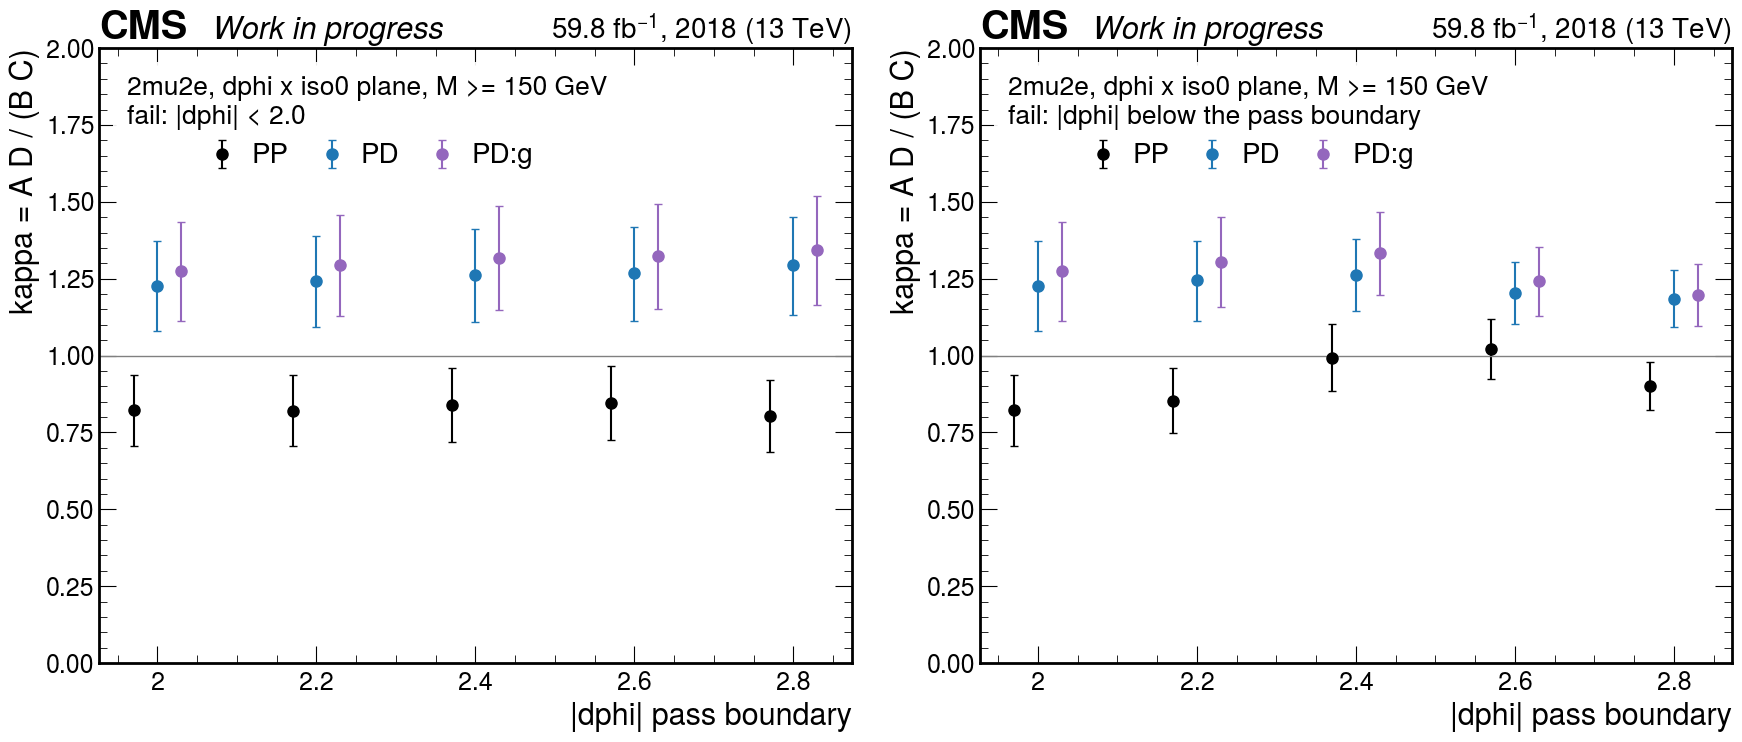

signal acceptance of the pass boundary relative to |dphi| >= 2.0 (A of the DD plane, M >= 150 GeV)


,|dphi| pass boundary,1000GeV_0p25GeV_0p2mm,1000GeV_1p2GeV_0p96mm,200GeV_0p25GeV_1p0mm,500GeV_0p25GeV_0p4mm,800GeV_0p25GeV_0p25mm,800GeV_0p25GeV_1p2mm,800GeV_1p2GeV_1p2mm
0,2.0,1.000,1.000,1.000,1.000,1.000,1.000,1.000
1,2.2,0.995,0.997,0.990,0.994,0.996,0.993,0.996
2,2.4,0.985,0.989,0.973,0.982,0.985,0.981,0.986
3,2.6,0.964,0.972,0.934,0.956,0.965,0.957,0.966
4,2.8,0.911,0.924,0.848,0.891,0.906,0.896,0.916


signal in the open regions of the search plane, nominal boundaries; 'A (stored xs)' is the yield at the cross section stored with the sample


,point,A (stored xs),acceptance vs reference A,S_B/S_A,S_C/S_A,S_D/S_A,A fraction at M>=200,A fraction at M>=300,A fraction at M>=400
0,2Mu2E_1000GeV_0p25GeV_0p2mm,1.5,0.985,0.0020,0.0081,0.0000,1.000,1.000,0.999
1,2Mu2E_1000GeV_1p2GeV_0p96mm,2.1,0.989,0.0021,0.0051,0.0000,1.000,1.000,0.997
2,2Mu2E_200GeV_0p25GeV_1p0mm,0.6,0.973,0.0019,0.0162,0.0000,0.524,0.008,0.001
3,2Mu2E_500GeV_0p25GeV_0p4mm,14.9,0.982,0.0013,0.0092,0.0000,1.000,0.998,0.977
4,2Mu2E_800GeV_0p25GeV_0p25mm,59.5,0.985,0.0015,0.0081,0.0000,1.000,1.000,0.998
5,2Mu2E_800GeV_0p25GeV_1p2mm,21.5,0.981,0.0020,0.0117,0.0000,1.000,0.999,0.997
6,2Mu2E_800GeV_1p2GeV_1p2mm,63.2,0.986,0.0022,0.0065,0.0000,1.000,0.999,0.996


In [2]:
fig = pp.boundary_figure(d2)
plt.show()
SIGNAL_POINTS = {"2mu2e": ["2Mu2E_200GeV_0p25GeV_1p0mm", "2Mu2E_500GeV_0p25GeV_0p4mm", "2Mu2E_800GeV_0p25GeV_0p25mm",
                           "2Mu2E_1000GeV_0p25GeV_0p2mm", "2Mu2E_800GeV_1p2GeV_1p2mm", "2Mu2E_1000GeV_1p2GeV_0p96mm",
                           "2Mu2E_800GeV_0p25GeV_1p2mm"],
                 "4mu": ["4Mu_200GeV_0p25GeV_1p0mm", "4Mu_500GeV_0p25GeV_0p4mm", "4Mu_800GeV_0p25GeV_0p25mm",
                         "4Mu_1000GeV_0p25GeV_0p2mm", "4Mu_800GeV_1p2GeV_1p2mm", "4Mu_1000GeV_1p2GeV_0p96mm",
                         "4Mu_800GeV_0p25GeV_1p2mm"]}
signals = {t: tl.sample_cubes(BASE, "signal", SIGNAL_POINTS[t], topologies=(t,)) for t in tl.TOPOLOGIES}
reference = dataclasses.replace(NOMINAL, dphi_pass=2.0)
rows = []
for dp in (2.0, 2.2, 2.4, 2.6, 2.8):
    cfg = dataclasses.replace(NOMINAL, dphi_pass=dp)
    rows.append({"|dphi| pass boundary": dp,
                 **{n.replace("2Mu2E_", ""): f"{ps.acceptance(c['2mu2e'], cfg, reference):.3f}" for n, c in signals["2mu2e"].items()}})
print("signal acceptance of the pass boundary relative to |dphi| >= 2.0 (A of the DD plane, M >= 150 GeV)")
display(pd.DataFrame(rows))
print("signal in the open regions of the search plane, nominal boundaries; 'A (stored xs)' is the yield at the cross section stored with the sample")
display(ps.signal_table(signals["2mu2e"], "2mu2e", NOMINAL, reference))

## 2. Which open plane looks like the search plane?

Three things can be compared between a candidate validation plane and the search plane without
opening A: the two ratios among failures, B/D ($|\Delta\phi|$ pass/fail among isolation failures)
and C/D (isolation pass/fail among $|\Delta\phi|$ failures), and the shapes behind them, the
$|\Delta\phi|$ distribution of the isolation-fail slice and the isolation distribution of the
$|\Delta\phi|$-fail slice (the shape tests contain the same B and D events as the ratios, so
they are not independent of them). Agreement is necessary for the transfer of anything, not
sufficient: `transfer_factors.ipynb` showed a pair of planes (PP → PD) whose B/D changes by a
factor 0.7 while A/C stays, so the pass-side ratios must be tested separately where A is open
(sections 3 and 4).

The candidates are PP (both prompt), DP (muon LJ displaced, egamma LJ prompt), PD (muon LJ prompt,
egamma LJ displaced), its photon-only and electron parts, and the 1–2-pixel-hit part of DP. The
second table shows what the egamma LJ of the search plane actually is: in its open regions it is
a photon-only LJ about 86% of the time, as in PD; PP and DP have no photon-only LJs because a
photon-only LJ has no track and so is displaced by definition.

,plane,kappa,B/D (plane),B/D pull vs DD,C/D (plane),C/D pull vs DD,"p(first-axis shape, iso-fail slice)","p(iso shape, first-axis-fail slice)"
0,PP,0.84 ± 0.12,7.85 -0.73 +0.80,+2.2,0.93 -0.12 +0.13,+0.3,0.15 (1278 vs 69 events),0.78 (305 vs 33 events)
1,DP,1.14 -0.87 +1.03,7.71 -2.87 +4.91,+1.3,0.71 -0.38 +0.78,-0.1,0.25 (73 vs 69 events),0.49 (16 vs 33 events)
2,PD,1.26 ± 0.15,5.44 -0.46 +0.51,+1.2,1.20 -0.13 +0.14,+0.9,0.46 (1175 vs 69 events),0.57 (435 vs 33 events)
3,PD:g,1.32 ± 0.17,5.32 -0.48 +0.53,+1.1,1.20 -0.14 +0.15,+0.9,0.44 (1014 vs 69 events),0.70 (385 vs 33 events)
4,PD:e,0.91 ± 0.34,6.25 -1.46 +1.95,+1.3,1.20 -0.35 +0.50,+0.7,0.64 (161 vs 69 events),0.08 (50 vs 33 events)
5,DP:mu1-2,1.29 -1.09 +1.36,8.17 -3.23 +5.83,+1.3,0.67 -0.38 +0.86,-0.2,0.21 (67 vs 69 events),0.27 (12 vs 33 events)
6,DD,NaN,3.57 -1.04 +1.50,NaN,0.79 -0.30 +0.48,NaN,NaN,NaN


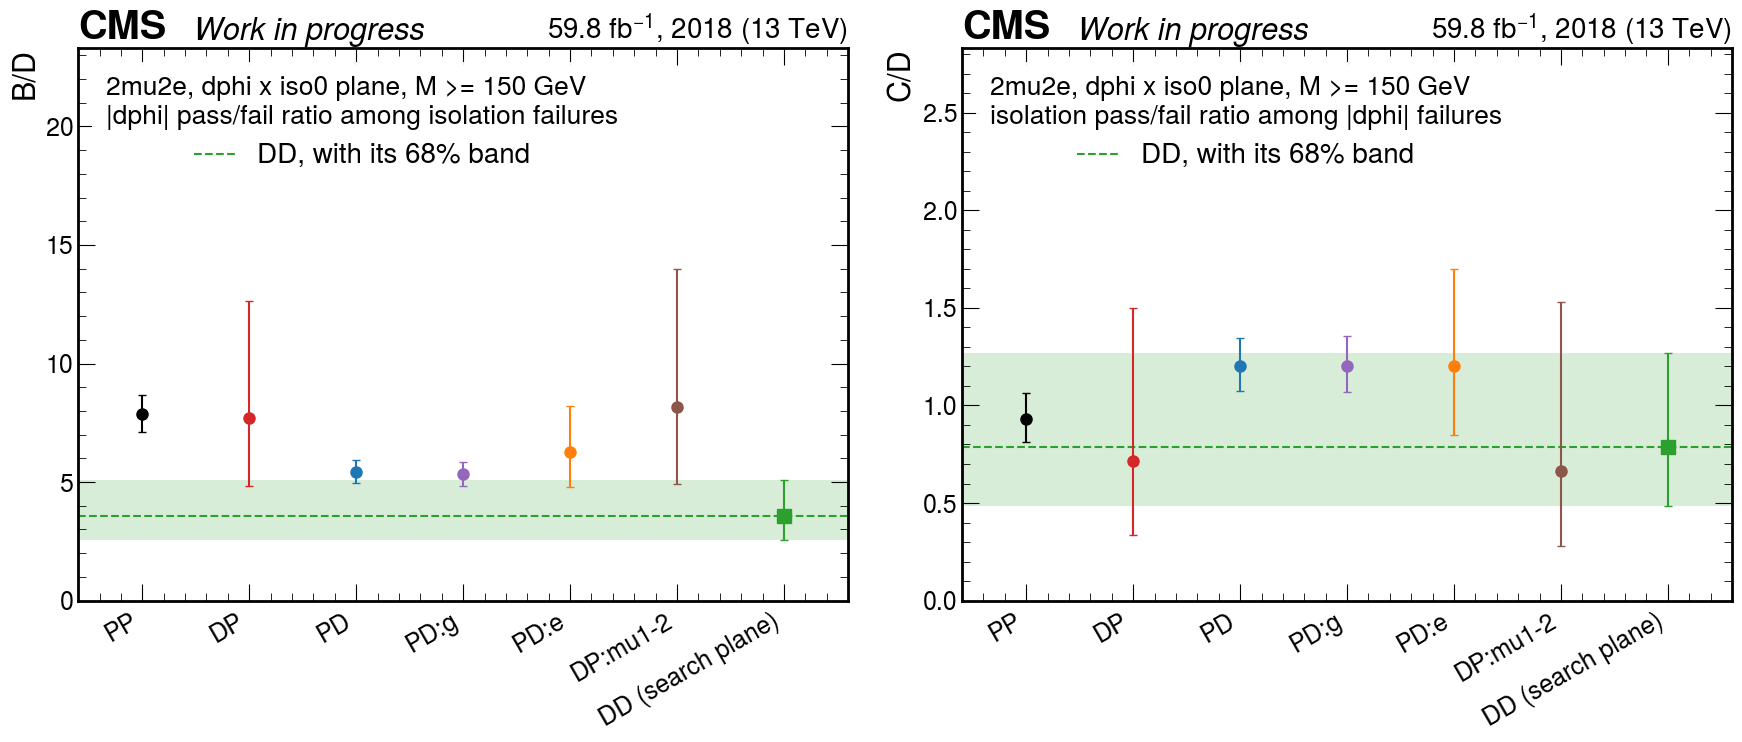

egamma LJ class per region, planes with a displaced egamma LJ, M >= 150 GeV


,plane,region,1 lost hit,2-9 lost hits,photon-only,photon-only share
0,PD,A,81,55,1207,0.90
1,PD,B,67,58,761,0.86
2,PD,C,11,13,172,0.88
3,PD,D,11,9,143,0.88
4,DD,A,blind,blind,blind,blind
5,DD,B,6,1,43,0.86
6,DD,C,0,1,10,0.91
7,DD,D,1,1,12,0.86


In [3]:
CANDIDATES = ["PP", "DP", "PD", "PD:g", "PD:e", "DP:mu1-2"]
display(ps.compatibility_table(d2, NOMINAL, CANDIDATES))
fig = pp.compatibility_figure(d2, CANDIDATES)
plt.show()
print("egamma LJ class per region, planes with a displaced egamma LJ, M >= 150 GeV")
display(ps.egm_class_table(d2, NOMINAL))

Reading: every candidate's B/D lies above the search plane's 3.6 (−1.0, +1.5), whose error
dominates all the pulls; PP is the farthest at 2.2σ (the largest of a dozen pulls, so about a
1.5σ effect after that choice), PD and its photon-only part are at 1.2σ. PP and PD do differ from
each other, by 2.8σ in B/D (7.9 ± 0.8 against 5.4 ± 0.5) and by 1.5σ the other way in C/D; it
is the search plane's own errors that cannot tell them apart. C/D agrees with the search plane
everywhere. The open ratios therefore do not single out a
plane; they only say that none is excluded and that PP fits least well. What does separate the
candidates is the egamma LJ: in the search plane it is a photon-only LJ 86–91% of the time, in PD
86–90%, in PP and DP never. DP and DP:mu1-2 are compatible as well but hold a dozen events in C
and D, so they cannot measure anything at the 20% level. The electron part PD:e agrees on the
ratios with 50 events in its $|\Delta\phi|$-fail slice and an isolation shape at p = 0.08.

## 3. Closure in PP and in PD: by muon pixel-hit class, by mass, by boundary variant

A validation plane is useful only if its κ is a property of the plane rather than of the sample
it happens to contain. Two handles are open in both PP and PD: the pixel-hit class of the prompt
muon LJ (3, 4, ≥ 5 hits) and the LJ-pair mass. The third table varies the boundaries that are not
fixed by the search-region definition (the variants are nested subsets of the nominal selection,
so they are not independent tests). The last table is the alternative of using the egamma LJ's
isolation as the second axis.

kappa by muon pixel-hit class (prompt classes in PP and PD; displaced classes in DP and DD), M >= 150 GeV


,plane,pixel hits,A,B,C,D,A/B,B/D,C/D,kappa
0,PP,all,797,1021,121,130,0.78 ± 0.04,7.85 -0.73 +0.80,0.93 -0.12 +0.13,0.84 ± 0.12
1,PP,3,162,282,31,28,0.57 -0.06 +0.06,10.07 -1.95 +2.46,1.11 -0.28 +0.38,0.52 ± 0.16
2,PP,4,453,547,71,66,0.83 -0.05 +0.06,8.29 -1.07 +1.24,1.08 -0.18 +0.22,0.77 ± 0.15
3,PP,>=5,182,192,19,36,0.95 -0.10 +0.11,5.33 -0.95 +1.17,0.53 -0.15 +0.20,1.80 -0.58 +0.65
4,DP,all,44,54,5,7,0.81 -0.16 +0.20,7.71 -2.87 +4.91,0.71 -0.38 +0.78,1.14 -0.87 +1.03
5,DP,0,2,5,1,1,0.40 -0.28 +0.80,5.00 -3.80 +29.24,1.00 -0.91 +10.08,0.40 -0.40 +2.99
6,DP,1-2,42,49,4,6,0.86 -0.18 +0.22,8.17 -3.23 +5.83,0.67 -0.38 +0.86,1.29 -1.09 +1.36
7,PD,all,1343,886,196,163,1.52 ± 0.07,5.44 -0.46 +0.51,1.20 -0.13 +0.14,1.26 ± 0.15
8,PD,3,317,206,54,36,1.54 -0.14 +0.15,5.72 -1.02 +1.25,1.50 -0.32 +0.40,1.03 -0.27 +0.25
9,PD,4,758,501,90,82,1.51 -0.09 +0.09,6.11 -0.72 +0.82,1.10 -0.17 +0.20,1.38 ± 0.24


kappa and A/B by LJ-pair mass bin; chi2 of the bins against the integrated kappa, in log space


,plane,bin,A,B,C,D,kappa,A/B
0,PP,150-200,292,320,46,71,1.41 ± 0.32,0.91 -0.07 +0.08
1,PP,200-300,306,381,42,43,0.82 ± 0.21,0.80 -0.06 +0.07
2,PP,300-400,121,194,21,9,0.27 -0.15 +0.12,0.62 -0.07 +0.08
3,PP,400-600,52,93,9,6,0.37 -0.29 +0.25,0.56 -0.10 +0.12
4,PP,>=600,26,33,3,1,0.26 -0.26 +0.39,0.79 -0.20 +0.27
5,PP,all,,,,,0.84 ± 0.12,chi2 of the bins 10.2 / 4
6,PD,150-200,574,321,100,72,1.29 ± 0.24,1.79 -0.12 +0.13
7,PD,200-300,494,325,60,58,1.47 ± 0.31,1.52 -0.11 +0.12
8,PD,300-400,171,144,20,20,1.19 ± 0.46,1.19 -0.13 +0.15
9,PD,400-600,79,79,10,12,1.20 -0.65 +0.68,1.00 -0.16 +0.19


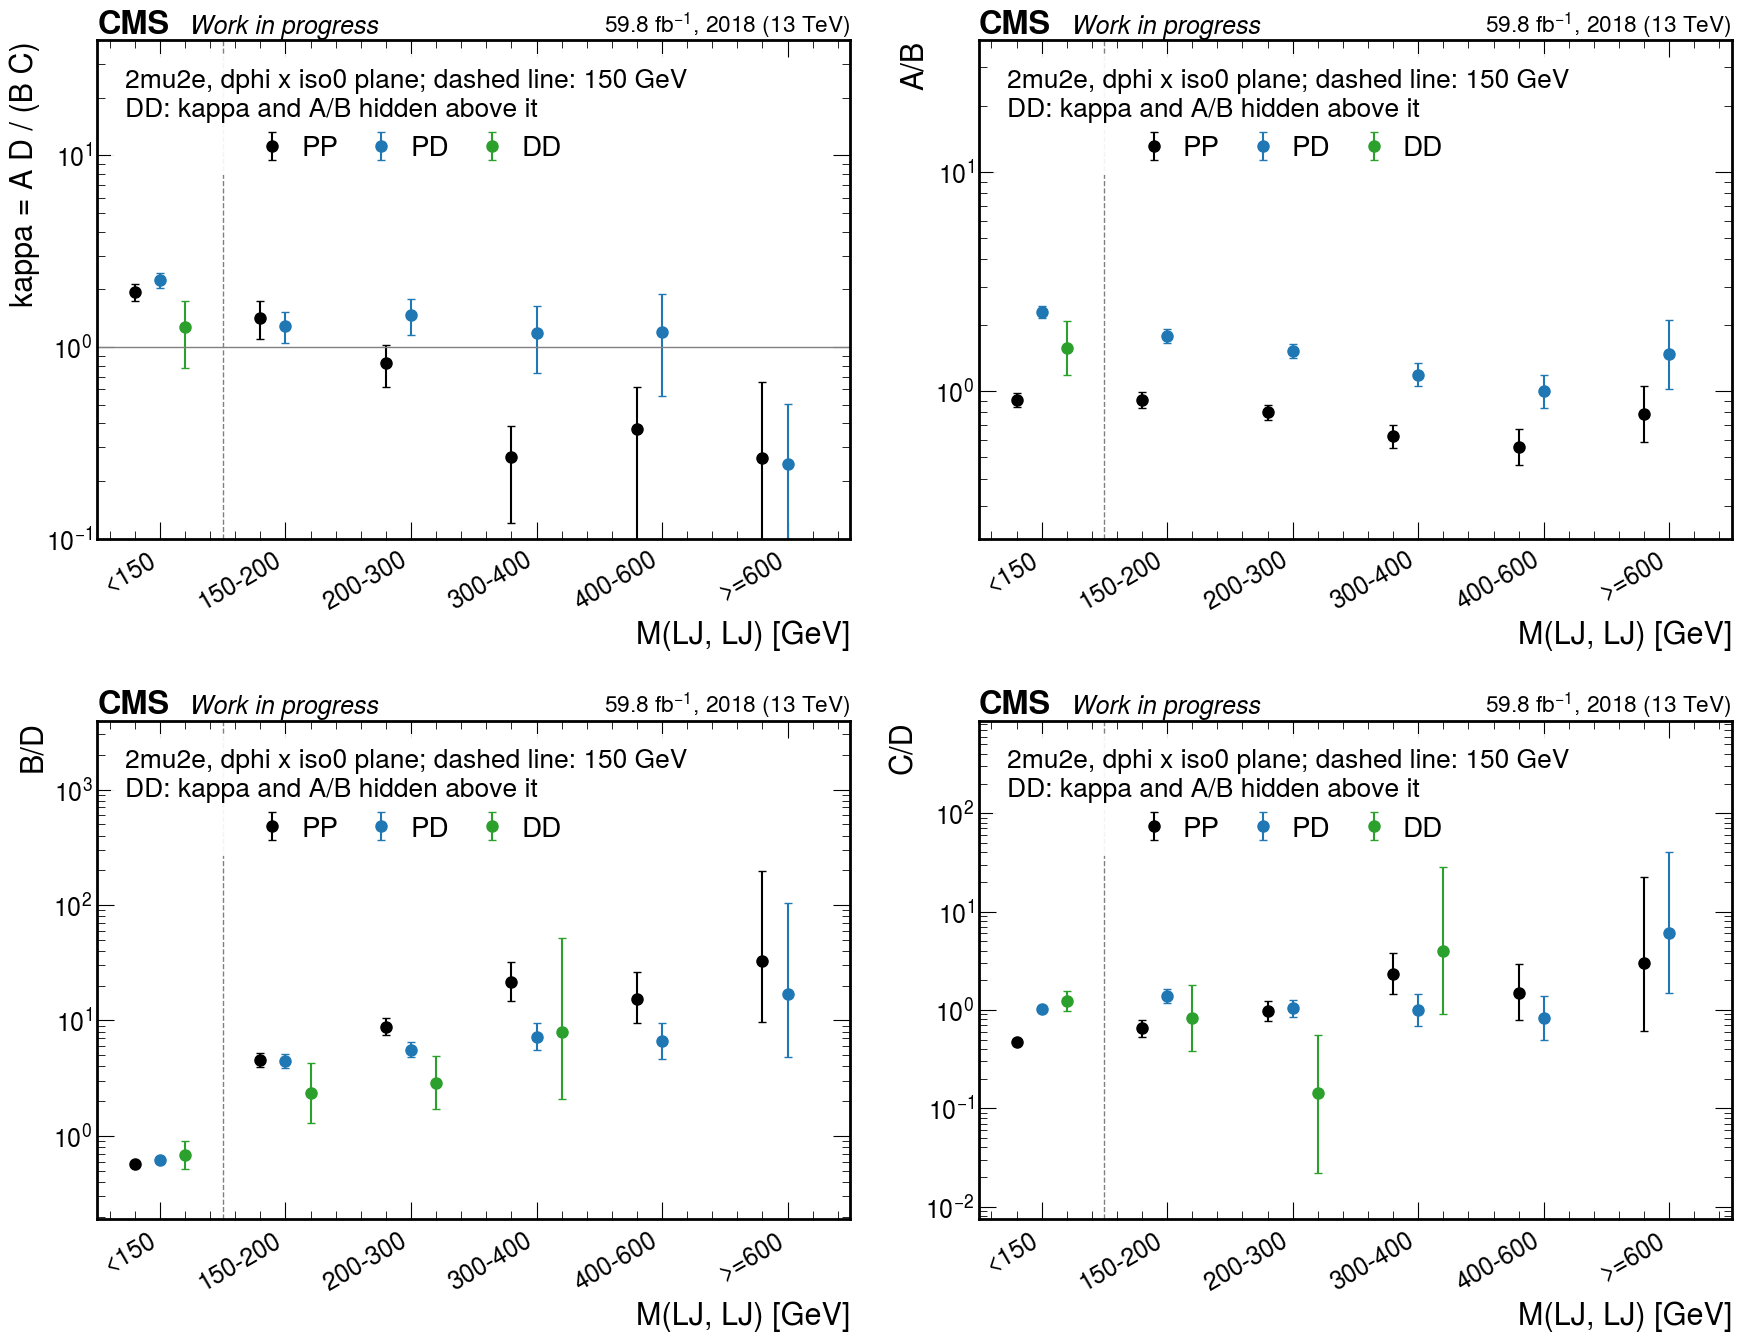

kappa of the validation planes for the boundary variants


,variant,in-plane estimate exists in DD,kappa PP,kappa PD
0,nominal,yes,0.84 ± 0.12,1.26 ± 0.15
1,iso1 < 0.25,yes,0.60 ± 0.11,1.27 ± 0.18
2,iso1 < 1,yes,0.89 ± 0.10,1.28 ± 0.14
3,iso0 pass < 0.2,yes,0.85 ± 0.13,1.24 ± 0.15
4,iso0 pass < 0.3,yes,0.87 ± 0.12,1.24 ± 0.15
5,no isolation buffer (fail >= 0.25),no (fail regions reach the hidden box),0.78 ± 0.10,1.17 ± 0.13
6,no |dphi| buffer (fail < 2.4),no (fail regions reach the hidden box),0.99 ± 0.11,1.26 ± 0.12


the alternative of using the egamma LJ's isolation as the second axis (|dphi| x iso1, leading muon LJ isolated at the event level)


,plane,A,B,C,D,A/B,B/D,C/D,A/C,B C/D,kappa
0,PP,797,973,121,96,0.82 ± 0.04,10.14 -1.08 +1.21,1.26 -0.17 +0.20,6.59 -0.64 +0.71,1226.4 ± 172.2,0.65 ± 0.10
1,PD,1343,437,196,43,3.07 -0.17 +0.18,10.16 -1.60 +1.92,4.56 -0.76 +0.92,6.85 -0.52 +0.57,1991.9 ± 348.7,0.67 -0.14 +0.12


In [4]:
print("kappa by muon pixel-hit class (prompt classes in PP and PD; displaced classes in DP and DD), M >= 150 GeV")
display(ps.class_table(d2, NOMINAL))
print("kappa and A/B by LJ-pair mass bin; chi2 of the bins against the integrated kappa, in log space")
display(ps.mass_table(d2, NOMINAL))
fig = pp.mass_figure(d2)
plt.show()
print("kappa of the validation planes for the boundary variants")
display(ps.variant_table(d2))
print("the alternative of using the egamma LJ's isolation as the second axis (|dphi| x iso1, leading muon LJ isolated at the event level)")
display(ps.plane_table(d2, ps.Config("dphi x iso1"), ["PP", "PD"]))

Reading: in PP, κ runs from 0.52 ± 0.16 at 3 pixel hits to 1.80 (−0.58, +0.65) at ≥ 5, from
1.41 ± 0.32 at 150–200 GeV to 0.27 (−0.15, +0.12) at 300–400 GeV (χ² 10.2 for 4 degrees of freedom
against the average, p = 0.04), and from 0.60 to 0.99 with the egamma-LJ isolation cut and the
$|\Delta\phi|$ buffer. Its A/B falls from 0.91 to 0.56 across the mass bins. PP's "closure" of
0.84 ± 0.12 is the average of a plane whose factorisation depends on the muon class, on the mass
and on the other LJ's isolation; none of these is the kind of number that transfers.

In PD, κ by class is 1.03/1.38/1.30, κ by mass bin is 1.29, 1.47, 1.19, 1.20 and 0.25 (−0.25, +0.26)
(χ² 1.3/4; the last bin, above 600 GeV, has one event in D), and every boundary variant gives
1.17–1.28. The subdivisions carry 20–55% errors, so this says that PD's κ is consistent with
one value, not that it is known to be one value at the 12% level in each of them; for the heavy
signal points what matters is κ$_{PD}$(M ≥ 300 GeV) = 1.05 ± 0.30. Its A/B does fall with mass,
1.79 → 1.00, which is why section 5 quotes the A/B factor per mass window. PD does not close at
κ = 1: it closes at 1.26 ± 0.15, which is what a usable correction looks like.

A hypothesis for why PP and PD differ, not tested here: in PP the egamma LJ is an electron with no
lost hits, mostly a real electron whose isolation is correlated with the event's activity and
hence with $|\Delta\phi|$ and with the muon LJ's isolation; the isolation cut on that LJ removes a
different fraction of events at each muon class and mass (the κ_PP dependence on the egamma
isolation cut points the same way). In PD and in the search plane the egamma LJ is a photon-like
object, and whatever makes it is not what sets the muon LJ's isolation. Against this, the
$|\Delta\phi|$ × egamma-isolation plane gives the same κ ≈ 0.65 in PP and in PD.

## 4. The muon LJ's pixel-hit class: 1–2 hits transfer, 0 hits do not

The search plane's muon LJ has ≤ 2 pixel hits. That is three populations: a track with 1 or 2
pixel hits, and the class with none, which is where the muon is a displaced-standalone (DSA)
muon or a track that missed the pixel detector altogether. In the open regions of the search plane
the pixel-0 class is a quarter of B, a fifth of D and one of the eleven events in C. Whether the
factors measured with a prompt muon LJ (≥ 3 hits) apply to these classes can be tested on two open
populations: with a prompt egamma LJ at M ≥ 150 GeV (DP classes 0–2 against PP classes 3–5+) and
with a displaced egamma LJ below 150 GeV (DD against PD, the only place where the fully displaced
corner is open); the same low-mass population in the plane of the two isolations is a variant of
the second test (its A and B contain the first's, as its $|\Delta\phi|$ requirement is 2.0
rather than 2.4), not a third population. For the prompt classes only, PD at M ≥ 150 GeV adds a
third view. The figure shows A/B and κ against the class; the first table lists the tests of the
step from prompt to 1–2 hits and to 0 hits, against the inclusive prompt plane and against each
prompt class; the next tables give the counts of the search plane by class, the 1-hit class and
the ≥ 5-hit prompt class on their own, and the composition of the signal.

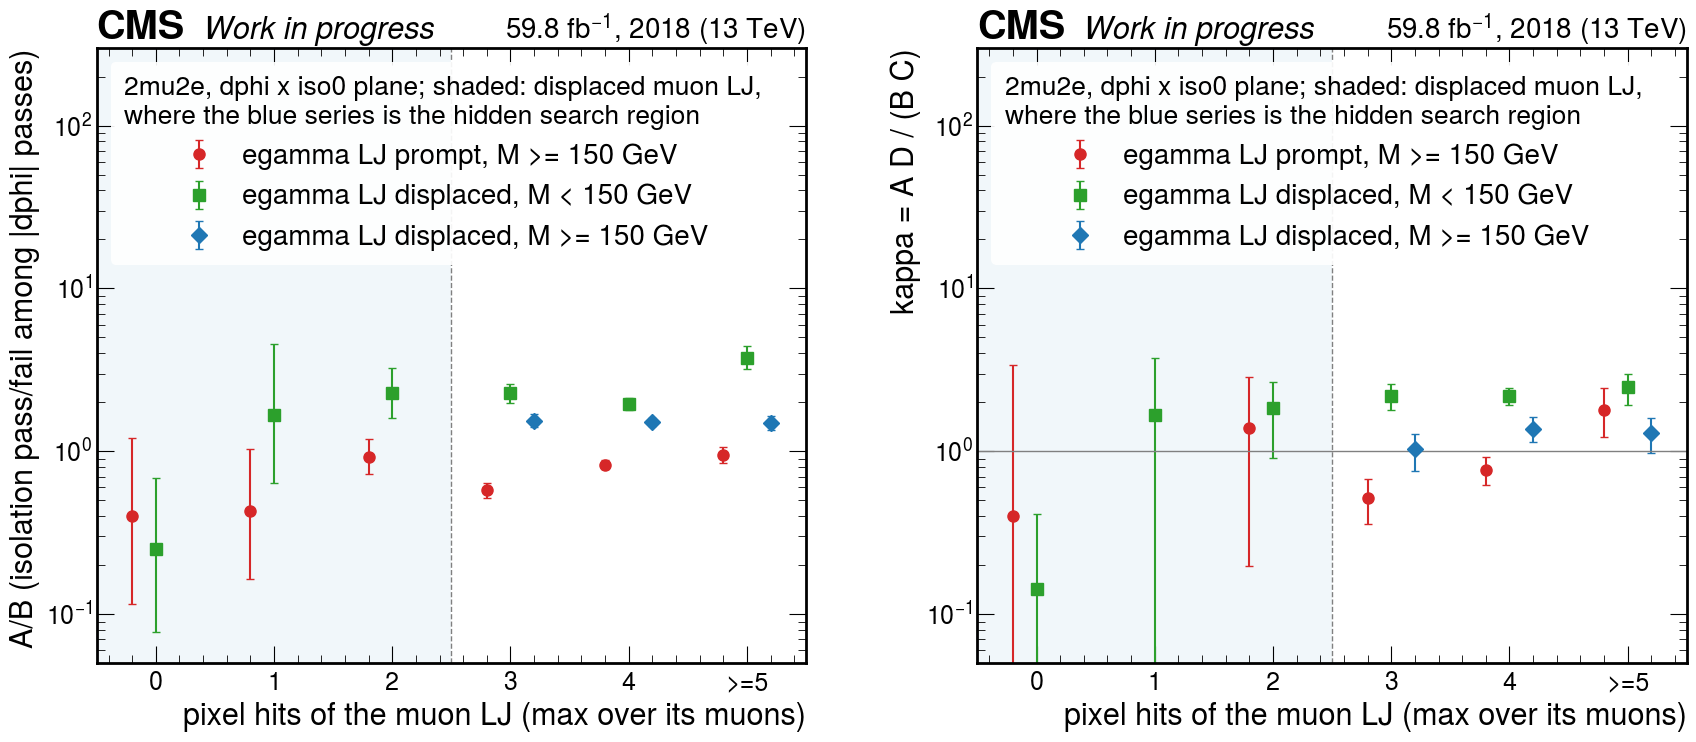

the open tests of the muon displacement step: A/B and kappa of the prompt plane, of the 1-2-hit class and of the 0-hit class


,test,prompt plane,1-2 pixel hits,ratio 1-2 hits / prompt,ratio 1-2 hits / prompt 3 hits,ratio 1-2 hits / prompt 4 hits,ratio 1-2 hits / prompt 5+ hits,0 pixel hits,ratio 0 hits / prompt
0,"A/B, EGM prompt, M>=150 (analysis plane)",PP: 0.78 ± 0.04 (797/1021),0.86 -0.18 +0.22 (42/49),1.10 -0.23 +0.29,1.49 -0.35 +0.42,1.04 -0.23 +0.28,0.90 -0.21 +0.25,0.40 -0.28 +0.80 (2/5),0.51 -0.37 +1.03
1,"A/B, EGM displaced, M<150 (analysis plane)",PD: 2.30 -0.14 +0.15 (878/382),2.17 -0.60 +0.84 (39/18),0.94 -0.27 +0.37,0.95 -0.30 +0.39,1.11 -0.32 +0.44,0.58 -0.19 +0.24,0.25 -0.17 +0.43 (2/8),0.11 -0.08 +0.19
2,"A/B, EGM displaced, M<150 (iso x iso plane)",PD: 1.94 -0.10 +0.11 (1036/534),2.05 -0.53 +0.72 (43/21),1.06 -0.28 +0.38,1.08 -0.31 +0.40,1.19 -0.32 +0.43,0.73 -0.22 +0.27,0.50 -0.28 +0.58 (4/8),0.26 -0.14 +0.30
3,"kappa, EGM displaced, M<150 (analysis plane)",PD: 2.23 ± 0.19,1.84 -0.83 +0.74,0.82 -0.38 +0.34,0.84 -0.40 +0.37,0.84 -0.39 +0.35,0.74 -0.36 +0.34,,
4,"kappa, EGM displaced, M<150 (iso x iso plane)",PD: 1.46 ± 0.14,1.07 -0.63 +0.52,0.73 -0.44 +0.36,0.60 -0.38 +0.32,0.88 -0.53 +0.44,0.54 -0.34 +0.29,,


counts per region in the search plane by muon pixel-hit class, M >= 150 GeV


,plane,pixel hits,A,B,C,D,A/B,B/D,C/D,kappa
0,DD,all,blind,50,11,14,n/a,3.57 -1.04 +1.50,0.79 -0.30 +0.48,n/a
1,DD,0,blind,13,1,3,n/a,4.33 -2.37 +6.12,0.33 -0.29 +1.29,n/a
2,DD,1-2,blind,37,10,11,n/a,3.36 -1.10 +1.69,0.91 -0.37 +0.63,n/a


the 1-hit class on its own, M >= 150 GeV (prompt egamma LJ) and M < 150 GeV (displaced egamma LJ), and the >= 5-hit prompt class at low mass


,plane,A,B,C,D,A/B,B/D,C/D,A/C,B C/D,kappa
0,DP:mu1,3,7,0,0,0.43 -0.26 +0.61,n/a,n/a,n/a,n/a,n/a
1,DD:mu1,blind,4,3,1,n/a,4.00 -3.09 +24.45,3.00 -2.38 +19.66,n/a,12.0 ± 15.1,n/a


,plane,A,B,C,D,A/B,B/D,C/D,A/C,B C/D,kappa
0,DD:mu1,5,3,7,7,1.67 -1.03 +2.92,0.43 -0.26 +0.61,1.00 -0.49 +0.96,0.71 -0.38 +0.78,3.0 ± 2.4,1.67 -1.67 +2.10
1,PD:mu5+,211,56,151,100,3.77 -0.56 +0.66,0.56 -0.09 +0.11,1.51 -0.19 +0.22,1.40 -0.15 +0.17,84.6 ± 15.7,2.50 -0.56 +0.51


signal composition of the search region (stored cross sections)


,point,search region (stored xs),pixel hits 0 / 1 / 2,prompt muon LJ / search region,lost hits 1 / 2-9 / photon-only,prompt egamma LJ / search region
0,2Mu2E_1000GeV_0p25GeV_0p2mm,1.5,0.56 / 0.22 / 0.22,0.42,0.13 / 0.19 / 0.68,0.17
1,2Mu2E_1000GeV_1p2GeV_0p96mm,2.1,0.61 / 0.20 / 0.18,0.35,0.13 / 0.18 / 0.69,0.14
2,2Mu2E_200GeV_0p25GeV_1p0mm,0.6,0.67 / 0.19 / 0.14,0.24,0.11 / 0.15 / 0.74,0.12
3,2Mu2E_500GeV_0p25GeV_0p4mm,14.9,0.63 / 0.20 / 0.17,0.30,0.12 / 0.18 / 0.70,0.15
4,2Mu2E_800GeV_0p25GeV_0p25mm,59.5,0.58 / 0.21 / 0.21,0.38,0.13 / 0.19 / 0.69,0.16
5,2Mu2E_800GeV_0p25GeV_1p2mm,21.5,0.74 / 0.15 / 0.11,0.18,0.05 / 0.10 / 0.85,0.07
6,2Mu2E_800GeV_1p2GeV_1p2mm,63.2,0.63 / 0.19 / 0.17,0.33,0.12 / 0.18 / 0.69,0.14


In [5]:
fig = pp.pixel_class_figure(d2)
plt.show()
print("the open tests of the muon displacement step: A/B and kappa of the prompt plane, of the 1-2-hit class and of the 0-hit class")
display(ps.muon_step_tests(d2, NOMINAL))
print("counts per region in the search plane by muon pixel-hit class, M >= 150 GeV")
display(ps.class_table(d2, NOMINAL, planes=("DD",)))
LOW = dataclasses.replace(NOMINAL, mass=(None, 150.0))
print("the 1-hit class on its own, M >= 150 GeV (prompt egamma LJ) and M < 150 GeV (displaced egamma LJ), and the >= 5-hit prompt class at low mass")
display(ps.plane_table(d2, NOMINAL, ["DP:mu1", "DD:mu1"]))
display(ps.plane_table(d2, LOW, ["DD:mu1", "PD:mu5+"]))
print("signal composition of the search region (stored cross sections)")
display(ps.signal_class_table(signals["2mu2e"], "2mu2e", NOMINAL))

Reading: against the inclusive prompt plane, the step from a prompt muon LJ to 1–2 hits changes
A/B by 1.10 (−0.23, +0.29) with a prompt egamma LJ at high mass and by 0.94 (−0.27, +0.37) with a
displaced egamma LJ at low mass (1.06 in the isolation-plane variant); κ changes by 0.82 (−0.38,
+0.34) and 0.73 (−0.44, +0.36) in the low-mass test and its variant. The step depends on which
prompt class is the reference: 1.49/1.04/0.90 against 3, 4 and ≥ 5 hits at high mass and
0.95/1.11/0.58 at low mass, where the ≥ 5-hit class has A/B = 3.77 against 2.0–2.3 for the others.
So the muon step is unity within the 25–35% precision of each test, with a spread between
references of the same size; 35% is the number to carry. In PD at M ≥ 150 GeV the three prompt
classes have the same A/B (1.54, 1.51, 1.50), so that plane's A/B does not care about the muon
LJ's pixel count where this can be checked at high mass.

The pixel-0 class is different: A/B is 0.40 (−0.28, +0.80) and 0.25 (−0.17, +0.43) in the two
populations (0.50 from 4 and 8 events in the isolation-plane variant), against 0.6–1.0 (prompt
egamma LJ, high mass) and 2.0–3.8 (displaced egamma LJ, low mass) for the classes with ≥ 2 hits.
Relative to the prompt plane of the same population the pixel-0 A/B is 0.51 (−0.37, +1.03) at
high mass and 0.11 (−0.08, +0.19) at low mass. The signal, on the other hand, is 56–74% pixel-0
in the search region, so this class cannot be cut away; it needs its own estimate, and these two
ratios are the only open measurements of it (section 5 shows that the high-mass one is taken
where the heavy signal points would sit). The 1-hit class is too small to place (3/7 and 5/3
events in A/B in the two tests, consistent with either neighbour); it is kept with the 2-hit class
because a muon with a pixel hit has a tracker track, and it is 8 of the 75 events in the open
regions of the search plane.

## 5. The estimate

Per mass window, for the 1–2-hit class: the in-plane $B\,C/D$ of the search plane, the same
multiplied by κ measured in PD, and B times the A/B measured in PD in the same window; for the
pixel-0 class, B times A/B of PD times the pixel-0/prompt ratio, for each of the two populations
that measure that ratio. The windows are the full analysis window and the ones the signal points
occupy (table in section 1: the 200 GeV point has half of its yield at 150–200 GeV and nothing
above 300; every heavier point has more than 99% above 300 GeV).

Two tables follow on what PD's region A contains besides the background of interest. The first
is the one simulated process that is present in PD and absent, by construction, from a plane with
a displaced muon LJ: Drell–Yan, a prompt muon pair with a photon-like egamma LJ. The simulation's
overall normalisation is not trusted (its total is a third of the data in PD's A and twice the data
in C and D), but the Drell–Yan yields themselves rest on 16 and 11 effective events in A and C
of the full window (4 and 3 above 300 GeV), and relative to the data they are 6–13% of A and
27–59% of C in the windows below 600 GeV (none of the six C events above 600 GeV). Subtracting
them moves κ$_{PD}$ from 1.26 to 1.73 ± 0.37 and A/B from 1.52 to 1.36 in the full window; the
table gives every window. The simulation has no Drell–Yan event in any region of the search plane
(so this is an upper bound on nothing), and there is no γ+jets, Wγ or Zγ sample although 86–90%
of these egamma LJs are photon-only. The stored histograms cannot test the Drell–Yan share in the
data; the muon LJ's own mass would (section 7, item 4).

The second table is the signal in the isolated corners of PD and DP, and of DP's two displaced
muon classes, at the stored cross sections, next to the data count there. The 18–42% of the
signal whose muon LJ is prompt lands in PD's corner: above 600 GeV two of the three 800 GeV
points put 21–23 events there against 25 in the data (the third, with the longer lifetime, 4),
which is the criterion on which the 4μ one-displaced corners were hidden; below 300 GeV the
corners hold no signal. DP's corner is more exposed: the same two points put 9–10 events there
against 15 in the data above 300 GeV, and in its pixel-0 part, where the high-mass pixel-0 ratio
of section 4 is measured, 5.6 events against 2 in the data at M ≥ 150 GeV. So the ratio 0.51 and
the pixel-0 estimate built on it come from a region that is as sensitive to the heavy signal
points as the search region, while the low-mass ratio 0.11 comes from regions with no signal.
Whether to hide PD's and DP's corners above some mass, or to keep them open and model the signal
there, is a decision for the group; the estimates below use them as they are.

In [6]:
WINDOWS = [("M >= 150", NOMINAL),
           ("150-300", dataclasses.replace(NOMINAL, mass=(150.0, 300.0))),
           ("200-300", dataclasses.replace(NOMINAL, mass=(200.0, 300.0))),
           ("M >= 300", dataclasses.replace(NOMINAL, mass=(300.0, None)))]
display(ps.estimate_table(d2, WINDOWS))
groups = tl.group_cubes(BASE, "bkg")
print("simulation per process group next to the data, nominal configuration, M >= 150 GeV")
display(ps.mc_composition_table(groups, d2, "2mu2e", NOMINAL, planes=("PD", "DD")))
print("Drell-Yan in PD and the plane's kappa and A/B with it subtracted from the data")
display(ps.subtracted_table(groups, d2, "2mu2e", WINDOWS + [("M >= 600", dataclasses.replace(NOMINAL, mass=(600.0, None)))]))
print("signal in region A of the one-LJ-displaced planes at the stored cross sections, next to the data count")
display(ps.signal_in_validation_table(signals["2mu2e"], "2mu2e", d2, WINDOWS + [("M >= 600", dataclasses.replace(NOMINAL, mass=(600.0, None)))],
                                      planes=("PD", "DP", "DP:mu1-2", "DP:mu0")))

,window,DD 1-2 hits B/C/D,in-plane B C/D,kappa PD,x kappa PD,A/B PD,B x A/B PD,DD 0 hits B,0 hits: B x A/B PD x step (egamma prompt),"0 hits: B x A/B PD x step (egamma displaced, M<150)"
0,M >= 150,37/10/11,33.6 ± 15.7,1.26 ± 0.15,42.4 ± 20.4,1.52 ± 0.07,56.1 ± 9.6,13,10.1 -7.7 +20.4 (step 0.51 -0.37 +1.03),2.1 -1.6 +3.8 (step 0.11 -0.08 +0.19)
1,150-300,21/5/10,10.5 ± 6.2,1.34 ± 0.18,14.1 ± 8.5,1.65 -0.08 +0.09,34.7 ± 7.8,13,11.0 -8.4 +22.3 (step 0.51 -0.37 +1.03),2.3 -1.7 +4.1 (step 0.11 -0.08 +0.19)
2,200-300,14/1/6,2.3 ± 2.6,1.47 ± 0.31,3.4 ± 3.9,1.52 -0.11 +0.12,21.3 ± 5.9,6,4.7 -3.9 +9.6 (step 0.51 -0.37 +1.03),1.0 -0.8 +1.8 (step 0.11 -0.08 +0.19)
3,M >= 300,16/5/1,80.0 ± 89.9,1.05 ± 0.30,84.0 ± 97.4,1.15 -0.10 +0.11,18.3 ± 4.9,0,0.0 -0.0 +1.1 (step 0.51 -0.37 +1.03),0.0 -0.0 +0.2 (step 0.11 -0.08 +0.19)


simulation per process group next to the data, nominal configuration, M >= 150 GeV


,plane,region,data,simulation,N_eff,DY,QCD,diboson,ttbar,kappa (simulation)
0,PD,A,1343,477.5 ± 144.7,10.9,133.9,309.9,1.0,32.7,0.43 ± 0.30
1,PD,B,886,875.8 ± 151.6,33.4,0.0,826.3,0.4,49.1,
2,PD,C,196,378.7 ± 169.8,5.0,67.5,301.3,0.0,9.8,
3,PD,D,163,296.1 ± 121.3,6.0,0.0,273.1,0.0,22.9,
4,DD,A,blind,32.3 ± 14.7,4.8,0.0,32.3,0.0,0.0,0.21 ± 0.26
5,DD,B,50,153.9 ± 118.9,1.7,0.0,147.4,0.0,6.5,
6,DD,C,11,14.9 ± 10.4,2.1,0.0,14.9,0.0,0.0,
7,DD,D,14,14.9 ± 7.5,3.9,0.0,14.9,0.0,0.0,


Drell-Yan in PD and the plane's kappa and A/B with it subtracted from the data


,window,data A/B/C/D,DY (simulation) A/B/C/D,DY N_eff A/B/C/D,DY / data,kappa,"kappa, DY subtracted",A/B,"A/B, DY subtracted"
0,M >= 150,1343/886/196/163,133.9/0.0/67.5/0.0,16.4/0.0/11.4/0.0,0.10/0.00/0.34/0.00,1.26 ± 0.15,1.73 ± 0.37,1.52 ± 0.07,1.36 ± 0.07
1,150-300,1068/646/160/130,105.2/0.0/57.8/0.0,12.6/0.0/9.1/0.0,0.10/0.00/0.36/0.00,1.34 ± 0.18,1.90 ± 0.48,1.65 -0.08 +0.09,1.49 ± 0.09
2,200-300,494/325/60/58,31.8/0.0/35.3/0.0,3.6/0.0/5.3/0.0,0.06/0.00/0.59/0.00,1.47 ± 0.31,3.34 ± 2.39,1.52 -0.11 +0.12,1.42 ± 0.12
3,M >= 300,275/240/36/33,28.8/0.0/9.7/0.0,3.9/0.0/3.0/0.0,0.10/0.00/0.27/0.00,1.05 ± 0.30,1.29 -0.51 +0.48,1.15 -0.10 +0.11,1.03 ± 0.11
4,M >= 600,25/17/6/1,3.2/0.0/0.0/0.0,1.0/0.0/0.0/0.0,0.13/0.00/0.00/0.00,0.25 ± 0.26,0.21 -0.21 +0.19,1.47 -0.45 +0.65,1.28 ± 0.47


signal in region A of the one-LJ-displaced planes at the stored cross sections, next to the data count


,window,plane,data A,data B,2Mu2E_1000GeV_0p25GeV_0p2mm in A,2Mu2E_1000GeV_1p2GeV_0p96mm in A,2Mu2E_200GeV_0p25GeV_1p0mm in A,2Mu2E_500GeV_0p25GeV_0p4mm in A,2Mu2E_800GeV_0p25GeV_0p25mm in A,2Mu2E_800GeV_0p25GeV_1p2mm in A,2Mu2E_800GeV_1p2GeV_1p2mm in A,largest signal / data A
0,M >= 150,PD,1343,886,0.6,0.7,0.1,4.5,22.9,3.9,21.0,0.02
1,M >= 150,DP,44,54,0.2,0.3,0.1,2.2,9.8,1.5,9.0,0.22
2,M >= 150,DP:mu1-2,42,49,0.1,0.1,0.0,0.8,4.1,0.4,3.3,0.10
3,M >= 150,DP:mu0,2,5,0.1,0.2,0.0,1.4,5.6,1.1,5.7,2.84
4,150-300,PD,1068,646,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.00
5,150-300,DP,29,34,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.00
6,150-300,DP:mu1-2,28,31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00
7,150-300,DP:mu0,1,3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
8,200-300,PD,494,325,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.00
9,200-300,DP,16,17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00


Reading, 1–2-hit class, M ≥ 150 GeV: the in-plane estimate is 34 ± 16, κ-corrected 42 ± 20,
and B × (A/B)$_{PD}$ gives 56 ± 10 (statistical); summed over the mass bins, with each bin's own
A/B, the last is 52. The two recipes are not independent checks of each other: their ratio is
the ratio of C/D between the search plane and PD, the pull of section 2. Above 300 GeV, where all
but the lightest signal point lives, the in-plane estimate is 80 ± 90 (one event in D) while
B × A/B gives 18 ± 5 from the 16 events in B and the PD ratio 1.15 ± 0.10 (1.03 ± 0.11 with
Drell–Yan subtracted, a subtraction that rests on 4 and 3 effective simulated events in that
window). In the 150–300 window, which supplies 35 of the 56 above, the two recipes are 14 ± 9
and 35 ± 8, 1.8σ apart, because C/D of the search plane is 0.5 there (5 and 10 events) against
1.2 in PD; this is where the compatibility is strained, and it is a window the heavy signal
points do not use. The pixel-0 class adds between 2 and 10 events over the full window depending
on which population sets its ratio, each with an error of its own size, and below one above 300
GeV; the 10 rests on the DP pixel-0 corner that the previous table shows to be signal-sensitive,
so if that corner is hidden the 2 is the only measurement.

## 6. 4μ

The 4μ histograms carry the same planes with the subleading muon LJ as object 1, and both
one-LJ-displaced corners are hidden. The open regions of the search plane are empty for every
configuration tried: one event in B and none in C or D of the $|\Delta\phi|$ plane, and 1/3/16 in
the plane of the two isolations (in-plane estimate 0.2 ± 0.2 before any correction). So the 4μ
background in the search region is at the level of one event whatever factor is used, B × (A/B)
of PP gives 1.3 ± 1.3, and nothing about the factor can be validated here: PP closes at
κ = 1.62 ± 0.55 in the $|\Delta\phi|$ plane with the buffered regions (1.38 ± 0.37 without buffers,
the status-report number) but at 9.2 ± 1.6 in the isolation plane, its pixel-class splits agree
within errors of order one, and below 150 GeV the three open planes give κ = 1.43, 0.91 and 0.38,
a plane-dependent closure already at low mass. What would give 4μ an estimate with a tested
factor is either opening the one-LJ-displaced corners after the same signal-contamination
assessment as in section 5 (the 4μ analogue of PD), or a per-LJ handle on the DSA-only muons
whose isolation and $\Delta\phi$ behaviour differs from tracker muons', which is not among the
stored variables.

In [7]:
d4 = data["4mu"]
print("4mu, M >= 150 GeV: the open regions of the search plane under three configurations, next to PP")
rows = []
for name, cfg in (("dphi x iso0, nominal", NOMINAL),
                  ("iso0 x iso1 (0.25/0.5 both), |dphi| >= 2.4", ps.Config("iso0 x iso1", 0.25, 0.5, 0.25, 0.5, 2.4, 2.4)),
                  ("iso0 x iso1 (0.5, no buffer), |dphi| >= 2.0", ps.Config("iso0 x iso1", 0.5, 0.5, 0.5, 0.5, 2.0, 2.0))):
    dd, pp_ = ps.regions(d4, cfg, "DD"), ps.regions(d4, cfg, "PP")
    pred = ps.prediction(dd)
    rows.append({"configuration": name, "DD B/C/D": "/".join(tl.fmt_count(dd[r]) for r in "BCD"),
                 "DD in-plane B C/D": "n/a" if np.isnan(pred[0]) else f"{pred[0]:.1f} ± {pred[1]:.1f}",
                 "PP A/B/C/D": "/".join(tl.fmt_count(pp_[r]) for r in "ABCD"), "kappa PP": tl.fmt(ps.kappa(pp_), 2),
                 "DD B x A/B PP": tl.fmt(tl._pred(dd["B"], tl.ratio(pp_["A"], pp_["B"])), 2)})
display(pd.DataFrame(rows))
display(ps.plane_table(d4, NOMINAL, ["PP", "PP:mu3", "PP:mu4", "PP:mu5+", "PP:sub3", "PP:sub4", "PP:sub5+"]))
print("4mu, M < 150 GeV")
display(ps.plane_table(d4, dataclasses.replace(NOMINAL, mass=(None, 150.0)), ["PP", "DP", "PD", "DD"]))

4mu, M >= 150 GeV: the open regions of the search plane under three configurations, next to PP


,configuration,DD B/C/D,DD in-plane B C/D,PP A/B/C/D,kappa PP,DD B x A/B PP
0,"dphi x iso0, nominal",1/0/0,n/a,264/198/23/28,1.62 ± 0.55,1.33 ± 1.34
1,"iso0 x iso1 (0.25/0.5 both), |dphi| >= 2.4",1/3/16,0.2 ± 0.2,174/59/293/915,9.21 -1.66 +1.57,2.95 ± 2.99
2,"iso0 x iso1 (0.5, no buffer), |dphi| >= 2.0",1/6/17,0.4 ± 0.4,462/229/757/972,2.59 ± 0.26,2.02 ± 2.03


,plane,A,B,C,D,A/B,B/D,C/D,A/C,B C/D,kappa
0,PP,264,198,23,28,1.33 -0.12 +0.14,7.07 -1.40 +1.77,0.82 -0.23 +0.31,11.48 -2.43 +3.15,162.6 ± 47.2,1.62 ± 0.55
1,PP:mu3,80,50,11,8,1.60 -0.28 +0.35,6.25 -2.22 +3.66,1.38 -0.59 +1.06,7.27 -2.22 +3.34,68.8 ± 33.4,1.16 -0.77 +0.68
2,PP:mu4,137,88,7,8,1.56 -0.21 +0.24,11.00 -3.79 +6.18,0.88 -0.42 +0.79,19.57 -7.02 +11.84,77.0 ± 40.7,1.78 ± 1.24
3,PP:mu5+,47,60,5,12,0.78 -0.15 +0.19,5.00 -1.51 +2.24,0.42 -0.21 +0.38,9.40 -3.99 +7.70,25.0 ± 13.7,1.88 -1.16 +1.64
4,PP:sub3,70,48,9,7,1.46 -0.27 +0.33,6.86 -2.57 +4.41,1.29 -0.60 +1.13,7.78 -2.59 +4.10,61.7 ± 32.4,1.13 -0.82 +0.73
5,PP:sub4,130,104,10,14,1.25 -0.16 +0.19,7.43 -2.03 +2.89,0.71 -0.28 +0.46,13.00 -4.03 +6.16,74.3 ± 31.6,1.75 -0.87 +0.96
6,PP:sub5+,64,46,4,7,1.39 -0.27 +0.33,6.57 -2.47 +4.24,0.57 -0.32 +0.70,16.00 -7.28 +15.38,26.3 ± 16.9,2.43 -1.92 +2.51


4mu, M < 150 GeV


,plane,A,B,C,D,A/B,B/D,C/D,A/C,B C/D,kappa
0,PP,332,399,126,216,0.83 -0.06 +0.07,1.85 -0.16 +0.17,0.58 -0.07 +0.07,2.63 -0.27 +0.31,232.8 ± 28.6,1.43 ± 0.21
1,DP,30,22,27,18,1.36 -0.37 +0.51,1.22 -0.37 +0.54,1.50 -0.44 +0.63,1.11 -0.29 +0.39,33.0 ± 12.3,0.91 -0.47 +0.42
2,PD,15,29,23,17,0.52 -0.16 +0.23,1.71 -0.50 +0.72,1.35 -0.42 +0.61,0.65 -0.21 +0.30,39.2 ± 14.5,0.38 ± 0.21
3,DD,2,0,3,1,n/a,0.00 -0.00 +5.30,3.00 -2.38 +19.66,0.67 -0.49 +1.70,n/a,n/a


## 7. Proposal

For the 2μ2e search region, with the planned definition (leading muon LJ isolation < 0.25, egamma LJ
isolation < 0.5, $|\Delta\phi| \ge 2.4$, pair mass ≥ 150 GeV, both LJs displaced):

1. **Validate in PD, not PP.** The plane with a prompt muon LJ and a displaced (in practice
   photon-only) egamma LJ has the search plane's egamma composition, is compatible with it on the
   open ratios and the fail-slice shapes, and its κ is consistent with one value (1.26 ± 0.15)
   across muon classes, mass bins and boundary variants. PP's κ depends on all three. The open
   ratios alone do not decide between the two; the composition and the stability do.
2. **Apply κ$_{PD}$ as a measured correction**, with two uncertainties on top of its 12%
   statistical error: the Drell–Yan composition of PD's A and C, which moves it to 1.73 ± 0.37
   if the simulated yields are right (section 5), and the transfer of κ across the muon step,
   tested only at low mass at the 35–45% level (0.82 and 0.73, section 4). The plane does not
   factorise at κ = 1 and there is no reason it should.
3. **Split the search plane by the muon LJ's pixel-hit class.** For 1–2 hits use
   B × (A/B)$_{PD}$ in the signal's mass window (M ≥ 300 GeV: 18 ± 5; M ≥ 150 GeV: 56 ± 10), with the
   κ-corrected in-plane estimate as the cross-check where it exists (42 ± 20 for M ≥ 150 GeV), a
   35% systematic from the open tests of the muon step and the Drell–Yan variation of A/B
   (−10%). For 0 hits use B × (A/B)$_{PD}$ × (pixel-0/prompt ratio), where the ratio is 0.51 or 0.11
   depending on the population that measures it: 2–10 events in the full window, below one above
   300 GeV, an estimate with an uncertainty of its own size that the signal's 56–74% pixel-0 share
   makes unavoidable. The 0.51 is measured in DP's pixel-0 corner, which at the stored cross
   sections holds three times more signal than data; if that corner is hidden, the 0.11 from the
   low-mass population (2 events in the full window) is the only measurement. Improving it means
   finding a larger open pixel-0 population, for which the 4μ channel's DSA studies are the
   natural source.
4. **Things to settle before the numbers are used:** the Drell–Yan share of PD's A and C, which
   the simulation puts at 6–13% and 27–59% on 3–16 effective events and which the stored
   histograms cannot test — the muon LJ's own mass can: a re-fill of the data and the Drell–Yan
   sample with that mass as a seventh axis shows a peak at the Z mass in PD's A and C if these
   are Z → μμ events with both muons in one LJ, and a cut at 75 GeV then removes them at no
   signal cost (the signal's muon-LJ mass is the dark-photon mass, below 2 GeV) and applies
   to every plane alike; the signal in the isolated corners of PD and DP (section 5: hide them
   above some mass, or model the signal there; the high-mass pixel-0 ratio depends on DP's); and
   the group's agreement to the open regions this uses (the search plane's B, C, D and its corner
   below 150 GeV; the isolated corners of DP and PD; in 4μ, the subleading-muon-LJ-non-isolated
   region of the search plane).

Not recommended: transferring B/D or C/D from PP, or using the other-LJ isolation as an ABCD axis
(the $|\Delta\phi|$ × egamma-isolation plane closes at κ ≈ 0.65 in both PP and PD).

## Files

`plane_search_lib.py` (planes and splits, configurations, regions, statistics, the scan, the tables
of this notebook), `test_plane_search_lib.py` (synthetic-cube tests of the region conventions, the
hidden box, the split planes and the table arithmetic), `plane_search_plots.py` (the four figures),
`_build_plane_search.py` (writes this notebook). The boundaries and planes shown were picked after
a scan of 1620 configurations × 17 planes with `plane_search_lib.scan` (every working point, buffer,
other-isolation cut and $|\Delta\phi|$ boundary of the three axis pairs); the compatibility
results of section 2 are therefore shown after that selection, and the scan's output is not kept in
the repository.